
# Notebook 3 — orchard_surveys.csv

**Projet Data Mining — Analyse de plusieurs datasets**

## Présentation du dataset

Ce notebook est consacré à l'analyse du fichier **orchard_surveys.csv**, qui contient des observations mensuelles réalisées sur 16 vergers de durian, de janvier 2019 à juin 2025.

On y retrouve plusieurs indicateurs liés à l'activité agricole : la densité de fleurs, le taux de nouaison (proportion de fleurs qui donnent un fruit), l'activité des autres pollinisateurs, la fertilisation, l'irrigation et le rendement. Certaines observations comportent également des remarques sur des événements particuliers, comme les tempêtes ou l'utilisation de pesticides.



Plusieurs pistes seront donc explorées :

- **H-C :** Tembara est la seule région où se trouvent à la fois une caverne et des vergers. On cherchera à savoir si la proximité de la caverne peut être associée à des différences dans les résultats des vergers.
- **H-G / H-J :** le verger AVL-TRP, situé dans une zone où des pannes cycliques ont été observées, présente-t-il des variations particulières pendant ces périodes ?
- **H-I :** la baisse acoustique observée à Tembara est-elle également associée à des changements dans les indicateurs agricoles ?





## Cellule 1 — Imports et chargement


In [ ]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import haversine_distances
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
sns.set_theme(style="whitegrid")

FILES = ["orchard_surveys.csv", "monitoring_sites.csv"]
try:
    from google.colab import files
    if not all(os.path.exists(f) for f in FILES):
        print("Téléverse les deux fichiers :", FILES)
        files.upload()
except ImportError:
    pass

def find(name):
    for p in [name, "/mnt/user-data/uploads/" + name]:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"{name} introuvable : téléverse-le")

raw = pd.read_csv(find(FILES[0]))
sites = pd.read_csv(find(FILES[1]))
sites["site_category"] = sites.site_category.str.strip().str.lower()     # même correction qu'aux notebooks 1 et 2

SPECIAL = ["AVL-TRP", "KNT-CHP"]        # sites à pannes cycliques trouvés au notebook 2
WINDOWS = [3, 4, 9, 10]                 # mois des pannes cycliques (mars, avril, septembre, octobre)
print("orchard_surveys :", raw.shape, "| sites :", sites.shape)
raw.head()

orchard_surveys : (1250, 11) | sites : (64, 14)


,orchard_survey_id,site_code,survey_period,orchard_area_ha,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity,fertilizer_use_index,irrigation_level,agricultural_disturbance_note
0,ORC-0000001,AVL-MAR,2019-01-01,24.1,40.3,34.7,20400.8,55.2,27.1,38.4,NaN
1,ORC-0000002,AVL-MAR,2019-02-01,24.1,33.8,41.6,17712.7,63.8,44.2,41.6,NaN
2,ORC-0000003,AVL-MAR,2019-03-01,24.1,55.1,57.3,28900.5,77.4,35.2,45.6,NaN
3,ORC-0000004,AVL-MAR,2019-04-01,24.1,90.2,48.7,21992.9,67.4,22.8,36.3,NaN
4,ORC-0000005,AVL-MAR,2019-05-01,24.1,80.7,61.4,27213.5,62.9,31.9,40.7,NaN


## Cellule 2 — Structure et défauts de qualité


In [ ]:
def pattern(x):
    return re.sub(r"[A-Za-z]", "a", re.sub(r"\d", "9", str(x)))

print("Dimensions :", raw.shape); print(raw.dtypes)
na = raw.isna().sum(); print("\nValeurs manquantes :"); print(na[na > 0])
print("\nDoublons (lignes entières) :", raw.duplicated().sum(), "| doublons d'identifiant :", raw.orchard_survey_id.duplicated().sum())
print(raw[raw.duplicated(keep=False)][["orchard_survey_id", "site_code", "survey_period"]])
print("\nSites :", raw.site_code.nunique(), "| lignes par site :", raw.site_code.value_counts().value_counts().to_dict())

print("\nFormats des colonnes lues comme du texte :")
for c in ["orchard_area_ha", "durian_flower_density", "durian_yield_kg", "fertilizer_use_index"]:
    print(f"  {c:<24}", raw[c].map(pattern).value_counts().to_dict())

print("\nNotes de perturbation (brutes) :"); print(raw.agricultural_disturbance_note.value_counts(dropna=False))
print("\nTaux de nouaison < 1 % :", (raw.fruit_set_rate_pct < 1).sum(), "lignes")
print(raw.loc[raw.fruit_set_rate_pct < 1, ["site_code", "survey_period", "fruit_set_rate_pct"]])

Dimensions : (1250, 11)
orchard_survey_id                 object
site_code                         object
survey_period                     object
orchard_area_ha                   object
durian_flower_density             object
fruit_set_rate_pct               float64
durian_yield_kg                   object
other_pollinator_activity        float64
fertilizer_use_index              object
irrigation_level                 float64
agricultural_disturbance_note     object
dtype: object

Valeurs manquantes :
agricultural_disturbance_note    1227
dtype: int64

Doublons (lignes entières) : 2 | doublons d'identifiant : 2
     orchard_survey_id site_code survey_period
892        ORC-0000893   AVL-NMQ    2021-11-01
1189       ORC-0001190   TMB-HQL    2020-08-01
1248       ORC-0000893   AVL-NMQ    2021-11-01
1249       ORC-0001190   TMB-HQL    2020-08-01

Sites : 16 | lignes par site : {78: 14, 79: 2}

Formats des colonnes lues comme du texte :
  orchard_area_ha          {'99.9': 1168, '9.9': 7

### Interprétation (cellule 2)

- 1 250 lignes dont 2 doublons exacts
- 4 colonnes numériques sont lues comme du texte.
- seulement 23 lignes sur 1 248 en ont une, mais écrites avec des espaces irréguliers.
- 8 taux de nouaison valent entre 0,47 et 0,60, alors que tous les autres sont entre 27 et 88.

## Cellule 3 — Nettoyage


In [ ]:
orc = raw.drop_duplicates().copy()                                       # 1) doublons exacts

def to_num(s):                                                          # 2) virgule décimale + unité collée
    return pd.to_numeric(s.astype(str).str.replace(",", ".", regex=False).str.replace(r"[^0-9.\-]", "", regex=True), errors="coerce")

n_comma = raw[["durian_flower_density", "fertilizer_use_index"]].astype(str).apply(lambda c: c.str.contains(",")).sum().sum()
n_unit = raw[["orchard_area_ha", "durian_yield_kg"]].astype(str).apply(lambda c: c.str.contains("[a-zA-Z]")).sum().sum()
for c in ["orchard_area_ha", "durian_flower_density", "durian_yield_kg", "fertilizer_use_index"]:
    orc[c] = to_num(orc[c])
print("virgules corrigées :", n_comma, "| unités retirées :", n_unit, "| valeurs non converties :", orc[["orchard_area_ha", "durian_flower_density", "durian_yield_kg", "fertilizer_use_index"]].isna().sum().sum())

orc = orc.rename(columns={"durian_flower_density": "flo", "fruit_set_rate_pct": "fs", "other_pollinator_activity": "pol",
                          "durian_yield_kg": "yld", "fertilizer_use_index": "fer", "irrigation_level": "irr"})

# 3) nouaison exprimée en fraction (0,5) au lieu de pourcentage (50) : x100
orc["fs_rescaled"] = orc.fs < 1
print("\nNouaisons < 1 (rééchelonnées x100) :", orc.fs_rescaled.sum(), "| valeurs avant :", sorted(orc.loc[orc.fs_rescaled, "fs"].round(3)))
orc.loc[orc.fs_rescaled, "fs"] = orc.loc[orc.fs_rescaled, "fs"] * 100
print("Nouaison après correction : min =", round(orc.fs.min(), 1),
      "| médiane =", round(orc.fs.median(), 1),
      "| max =", round(orc.fs.max(), 1))

# 4) notes : espaces parasites
orc["note"] = orc.agricultural_disturbance_note.str.strip().str.replace(r"\s+", " ", regex=True)
print("\nNotes après normalisation :"); print(orc.note.value_counts(dropna=False))

# 5) dates, rendement par hectare, saturations, région
orc["t"] = pd.to_datetime(orc.survey_period); orc["y"] = orc.t.dt.year; orc["m"] = orc.t.dt.month; orc["ym"] = orc.t.dt.to_period("M")
orc["yha"] = orc.yld / orc.orchard_area_ha
orc["flo_sat"] = orc.flo == 100
orc = orc.merge(sites[["site_code", "region", "latitude", "longitude"]], on="site_code", how="left")
orc["zone"] = orc.site_code.str[:3]
print("\nLignes finales :", len(orc), "| vergers :", orc.site_code.nunique())
orc.head(3)

virgules corrigées : 8 | unités retirées : 10 | valeurs non converties : 0

Nouaisons < 1 (rééchelonnées x100) : 8 | valeurs avant : [0.467, 0.543, 0.549, 0.555, 0.561, 0.568, 0.581, 0.595]
Nouaison après correction : min = 27.3 | médiane = 53.0 | max = 87.7

Notes après normalisation :
note
NaN                               1225
storm-related flower loss           18
elevated pesticide application       5
Name: count, dtype: int64

Lignes finales : 1248 | vergers : 16


,orchard_survey_id,site_code,survey_period,orchard_area_ha,flo,fs,yld,pol,fer,irr,agricultural_disturbance_note,fs_rescaled,note,t,y,m,ym,yha,flo_sat,region,latitude,longitude,zone
0,ORC-0000001,AVL-MAR,2019-01-01,24.1,40.3,34.7,20400.8,55.2,27.1,38.4,NaN,False,NaN,2019-01-01,2019,1,2019-01,846.506224,False,Eastern Avelora Agricultural Cluster,7.41,101.69,AVL
1,ORC-0000002,AVL-MAR,2019-02-01,24.1,33.8,41.6,17712.7,63.8,44.2,41.6,NaN,False,NaN,2019-02-01,2019,2,2019-02,734.966805,False,Eastern Avelora Agricultural Cluster,7.41,101.69,AVL
2,ORC-0000003,AVL-MAR,2019-03-01,24.1,55.1,57.3,28900.5,77.4,35.2,45.6,NaN,False,NaN,2019-03-01,2019,3,2019-03,1199.190871,False,Eastern Avelora Agricultural Cluster,7.41,101.69,AVL


## Cellule 4 — Contrôles d'intégrité


In [ ]:
print("Mois par verger :", orc.groupby("site_code").size().value_counts().to_dict(), "| période :", orc.ym.min(), "->", orc.ym.max())
print("Doublons verger x mois :", orc.duplicated(["site_code", "ym"]).sum(), "| dates hors 1er du mois :", (orc.t.dt.day != 1).sum())
print("Surface constante par verger ? valeurs distinctes par site :", orc.groupby("site_code").orchard_area_ha.nunique().value_counts().to_dict())

print("\nSaturations de la densité de fleurs (= 100) :", orc.flo_sat.sum(), f"({orc.flo_sat.mean():.1%} des lignes)")
print(orc.groupby("site_code").flo_sat.sum().sort_values(ascending=False).head(6).to_dict())
print("Autres variables aux bornes : fertilisation = 5,0 ->",
      (orc.fer == 5.0).sum(),
      "| nouaison max =", round(orc.fs.max(), 1),
      "| pollinisateurs max =", orc.pol.max())

# Le rendement est-il cohérent avec surface x fleurs x nouaison ?
proxy = orc.orchard_area_ha * orc.flo * orc.fs / 100
print("\nCorrélation de Spearman rendement ~ surface x fleurs x nouaison :", round(stats.spearmanr(orc.yld, proxy)[0], 2))
print("Corrélation de Spearman rendement ~ surface seule :", round(stats.spearmanr(orc.yld, orc.orchard_area_ha)[0], 2))
print("Rendement par hectare : min", round(orc.yha.min(), 0),
      "| médiane", round(orc.yha.median(), 0),
      "| max", round(orc.yha.max(), 0))

q1, q3 = orc.yha.quantile([.25, .75]); iqr = q3 - q1
print("IQR rendement/ha : bornes [%.0f ; %.0f] -> %d valeurs hors bornes" % (q1 - 1.5 * iqr, q3 + 1.5 * iqr, ((orc.yha < q1 - 1.5 * iqr) | (orc.yha > q3 + 1.5 * iqr)).sum()))

Mois par verger : {78: 16} | période : 2019-01 -> 2025-06
Doublons verger x mois : 0 | dates hors 1er du mois : 0
Surface constante par verger ? valeurs distinctes par site : {1: 16}

Saturations de la densité de fleurs (= 100) : 99 (7.9% des lignes)
{'TMB-BRC': 14, 'AVL-TRP': 10, 'AVL-NMQ': 8, 'AVL-MAR': 8, 'AVL-NFR': 7, 'AVL-YAU': 6}
Autres variables aux bornes : fertilisation = 5,0 -> 2 | nouaison max = 87.7 | pollinisateurs max = 93.7

Corrélation de Spearman rendement ~ surface x fleurs x nouaison : 0.81
Corrélation de Spearman rendement ~ surface seule : 0.9
Rendement par hectare : min 393.0 | médiane 1038.0 | max 1816.0
IQR rendement/ha : bornes [518 ; 1553] -> 10 valeurs hors bornes


### Interprétation (cellule 4)

- Table complète
- Densité de fleurs saturée à 100 pour 99 lignes (7,9 %)
- Le rendement dépend d'abord de la surface** (Spearman 0,90)
- 10 valeurs de rendement/ha sortent des bornes de l'IQR (518 à 1 553) : on les garde (extrêmes plausibles, étudiés cellule 12).

## Cellule 5 — Statistiques descriptives et corrélations
 quelles variables sont liées à la nouaison, et lesquelles ne sont liées à rien.

                  count     mean      std     min      25%      50%      75%       max
flo              1248.0     63.1     22.4    17.0     46.0     58.6     84.0     100.0
fs               1248.0     53.6      9.3    27.3     47.0     53.0     59.4      87.7
pol              1248.0     59.4      9.4    27.9     53.3     59.5     65.7      93.7
yld              1248.0  47150.9  21479.6  3971.3  31192.9  46774.6  62028.3  118638.7
yha              1248.0   1041.2    197.4   392.8    905.8   1038.3   1164.7    1815.7
fer              1248.0     38.3     10.7     5.0     31.0     38.1     45.5      74.4
irr              1248.0     40.0      9.1    11.5     33.8     39.5     45.5      81.0
orchard_area_ha  1248.0     45.5     19.0     6.0     29.9     49.4     59.3      84.7


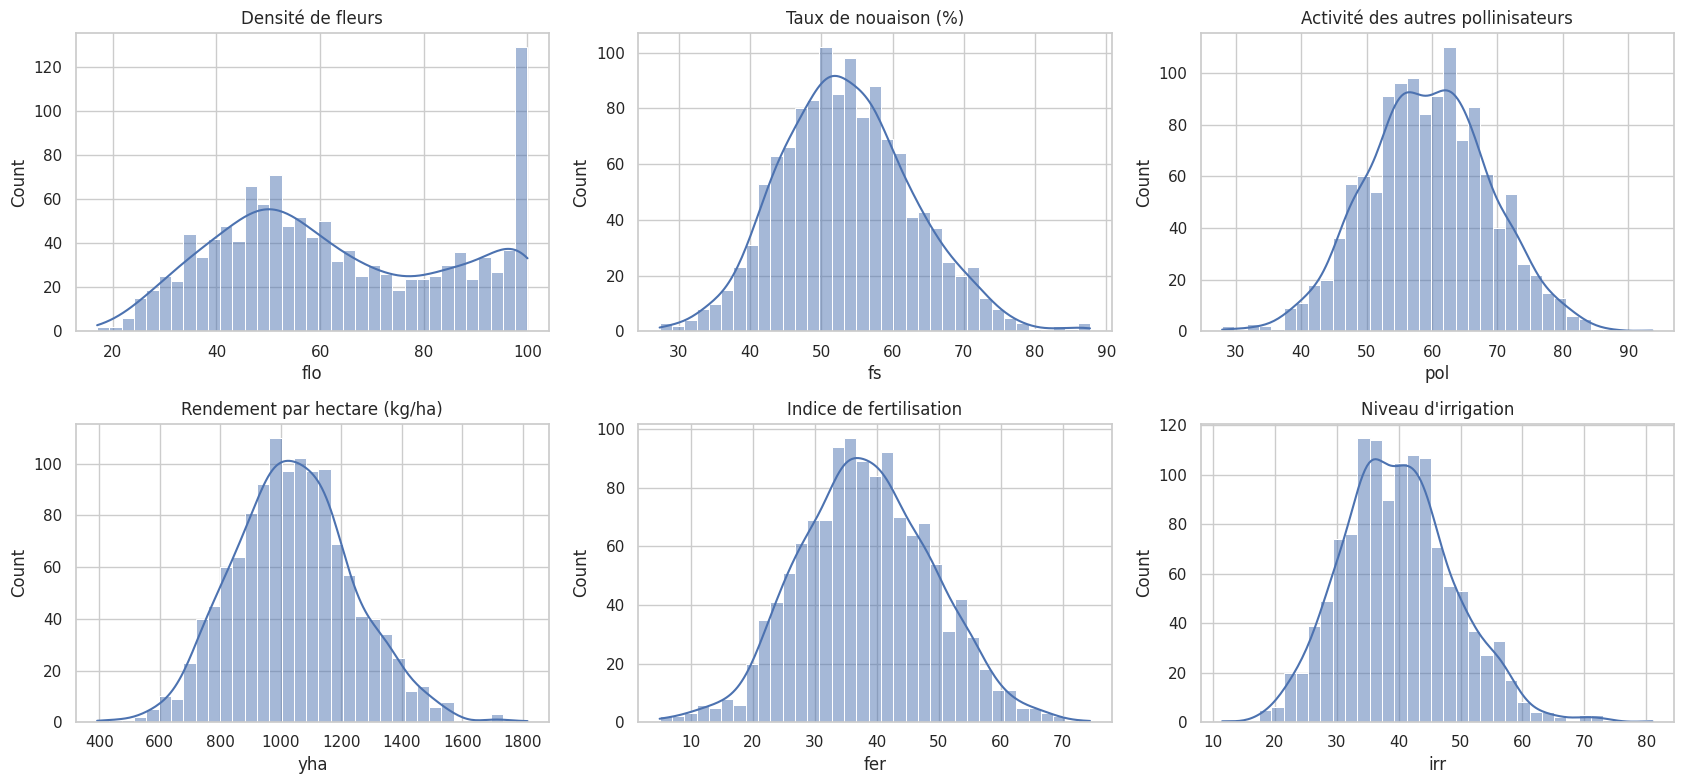


Corrélations de Spearman :
      flo    fs   pol   yha   fer   irr
flo  1.00  0.66  0.03  0.59  0.02 -0.04
fs   0.66  1.00  0.43  0.91  0.03 -0.02
pol  0.03  0.43  1.00  0.40 -0.03  0.02
yha  0.59  0.91  0.40  1.00  0.04  0.07
fer  0.02  0.03 -0.03  0.04  1.00  0.04
irr -0.04 -0.02  0.02  0.07  0.04  1.00

Écart maximal Spearman - Pearson : 0.03


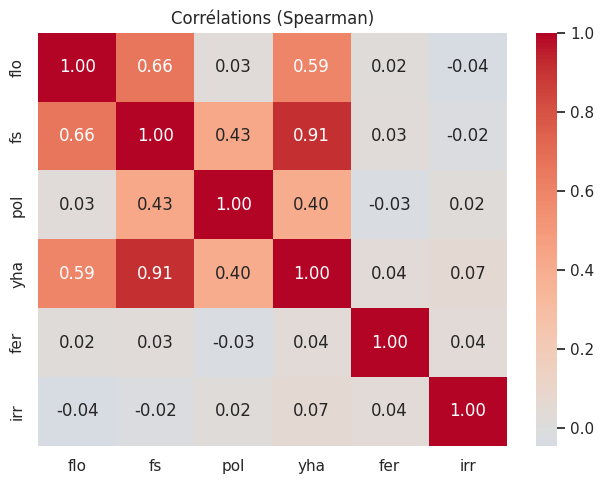

In [ ]:
V = ["flo", "fs", "pol", "yld", "yha", "fer", "irr", "orchard_area_ha"]
print(orc[V].describe().round(1).T)

fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for a, (v, t) in zip(ax.ravel(), [("flo", "Densité de fleurs"), ("fs", "Taux de nouaison (%)"), ("pol", "Activité des autres pollinisateurs"),
                                  ("yha", "Rendement par hectare (kg/ha)"), ("fer", "Indice de fertilisation"), ("irr", "Niveau d'irrigation")]):
    sns.histplot(orc[v], bins=35, kde=True, ax=a); a.set_title(t)
plt.tight_layout(); plt.show()

cs = orc[["flo", "fs", "pol", "yha", "fer", "irr"]].corr(method="spearman")
cp = orc[["flo", "fs", "pol", "yha", "fer", "irr"]].corr(method="pearson")
print("\nCorrélations de Spearman :"); print(cs.round(2))
print("\nÉcart maximal Spearman - Pearson :", round((cs - cp).abs().max().max(), 2))
fig, ax = plt.subplots(figsize=(6.5, 5)); sns.heatmap(cs, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax); ax.set_title("Corrélations (Spearman)")
plt.tight_layout(); plt.show()

### Interprétation (cellule 5)

- La nouaison explique le rendement, elle-même alimentée par les fleurs et les pollinisateurs : la chaîne agronomique attendue est là.


## Cellule 6 — Comparaison des 16 vergers
classement des vergers par nouaison, et les variables où les vergers ne diffèrent **pas**.

          zone  area   flo    fs   pol     yha   fer   irr  notes
site_code                                                        
TMB-BRC    TMB  25.7  67.8  65.8  70.0  1261.3  38.5  39.9      0
AVL-VEL    AVL  62.3  62.8  57.7  64.3  1120.8  36.9  40.5      0
TMB-HQL    TMB  44.2  67.3  56.1  61.3  1077.1  38.1  39.4      2
AVL-NMQ    AVL  31.3  61.7  55.6  61.2  1091.3  38.7  39.9      0
AVL-ORR    AVL  59.7  63.3  55.1  61.0  1071.0  39.4  41.0      0
AVL-TRP    AVL  54.7  69.0  55.0  58.5  1066.8  38.5  39.6      0
TMB-SKZ    TMB  51.0  63.8  54.3  62.4  1058.1  39.4  39.0      0
AVL-YAU    AVL   6.0  63.3  54.0  59.8  1054.1  38.0  39.4      1
AVL-MAR    AVL  24.1  63.1  53.8  64.4  1041.9  37.6  38.7      1
AVL-ECJ    AVL  60.9  61.8  53.5  61.4  1054.5  38.4  40.8      0
AVL-RBC    AVL  59.2  59.8  51.6  58.0  1023.2  37.7  42.3      0
AVL-KAR    AVL  84.7  61.2  50.9  55.2  1010.8  38.1  41.4      0
AVL-NFR    AVL  24.4  62.2  50.4  54.7   978.8  38.5  39.5      1
AVL-HUA   

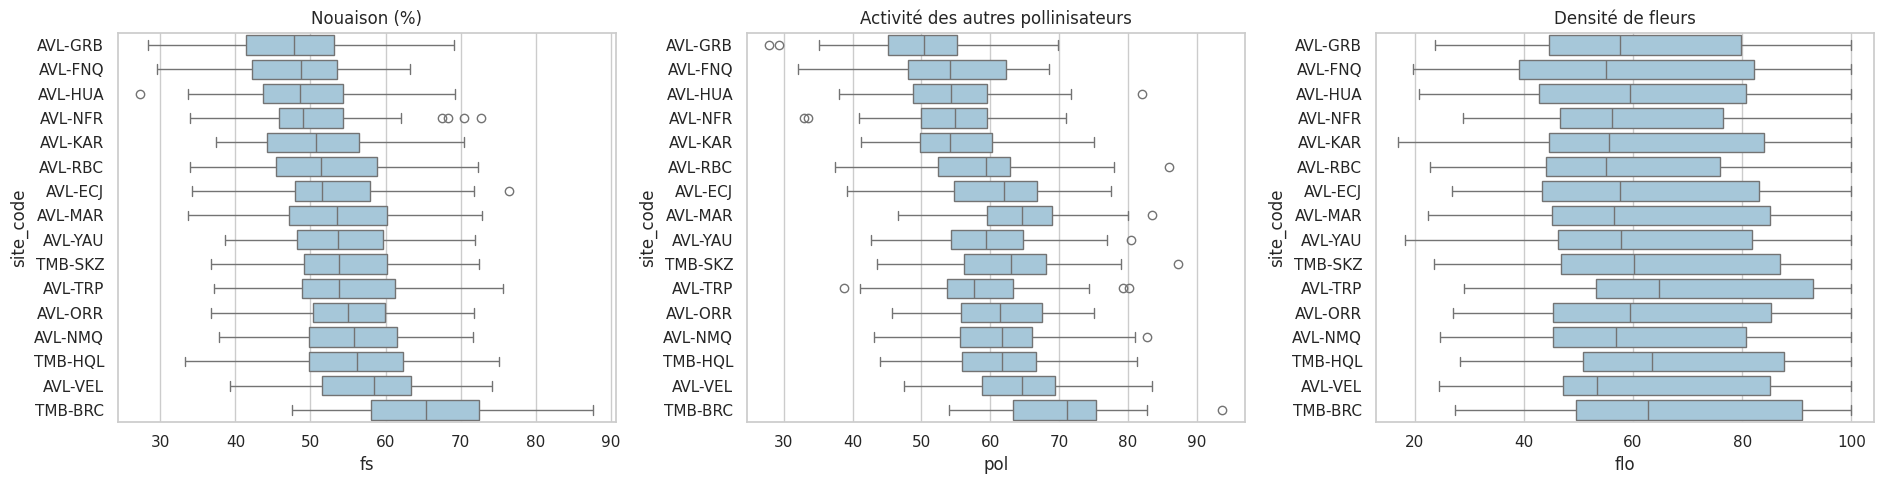

In [ ]:
agg = orc.groupby("site_code").agg(zone=("zone", "first"), area=("orchard_area_ha", "first"), flo=("flo", "mean"), fs=("fs", "mean"),
                                    pol=("pol", "mean"), yha=("yha", "mean"), fer=("fer", "mean"), irr=("irr", "mean"), notes=("note", lambda x: x.notna().sum()))
print(agg.sort_values("fs", ascending=False).round(1))

print("\nLes vergers diffèrent-ils entre eux ? (Kruskal-Wallis, 16 groupes)")
for v in ["fs", "pol", "flo", "yha", "fer", "irr"]:
    h, p = stats.kruskal(*[g[v].values for _, g in orc.groupby("site_code")]); print(f"  {v:<4} H = {h:7.1f} | p = {p:.2e}")

print("\nTembara (3 vergers) vs Avelora (13 vergers) :")
for v in ["fs", "pol", "flo", "yha"]:
    a, b = orc[orc.zone == "TMB"][v], orc[orc.zone == "AVL"][v]
    print(f"  {v:<4} Tembara {a.mean():6.1f} | Avelora {b.mean():6.1f} | Mann-Whitney p = {stats.mannwhitneyu(a, b)[1]:.2e}")

order = agg.sort_values("fs").index
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for a, (v, t) in zip(ax, [("fs", "Nouaison (%)"), ("pol", "Activité des autres pollinisateurs"), ("flo", "Densité de fleurs")]):
    sns.boxplot(data=orc, y="site_code", x=v, order=order, color="#9ecae1", ax=a); a.set_title(t)
plt.tight_layout(); plt.show()

### Interprétation (cellule 6)

ESQ l'avantage de Tembara est-il un effet de zone ou un effet TMB-BRC seul ?.

## Cellule 7 — Saisonnalité, ACF, décomposition, phase
 décrire le cycle annuel des vergers .



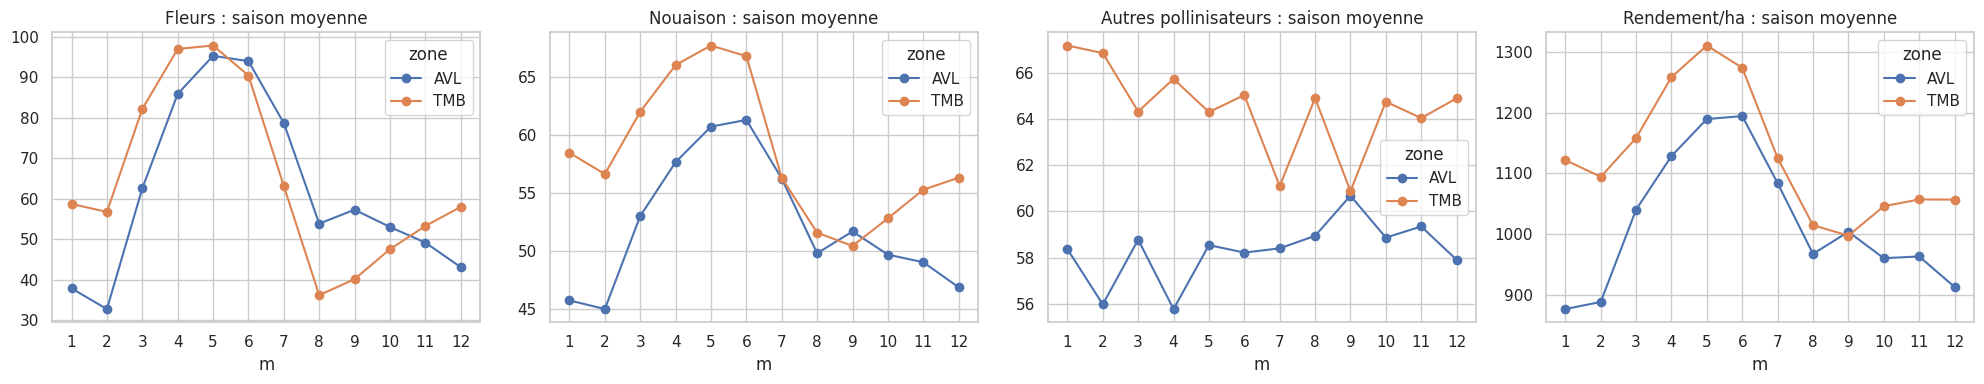

Amplitude saisonnière (max-min)/moyenne par zone :
      flo    fs   pol   yha
AVL  1.00  0.31  0.08  0.31
TMB  0.93  0.29  0.10  0.28
ACF flo  (Avelora) : lag 6 = -0.48 | lag 12 = +0.83 | lag 24 = +0.69
ACF fs   (Avelora) : lag 6 = -0.46 | lag 12 = +0.77 | lag 24 = +0.61
ACF pol  (Avelora) : lag 6 = -0.07 | lag 12 = +0.18 | lag 24 = +0.27
Nouaison Avelora - écart-type : série 5.69 | saison 5.48 | résidu 1.43

Phase moyenne de la saison (1 = janvier, 6 = juin) :
     phase_fleurs       phase_nouaison      
             mean   std           mean   std
zone                                        
AVL          5.78  0.07           5.78  0.31
TMB          4.20  0.11           4.12  0.41


In [ ]:
def acf(x, nlags=36):
    x = np.asarray(x, float) - np.mean(x); den = (x ** 2).sum()
    return np.array([1.0] + [(x[:-k] * x[k:]).sum() / den for k in range(1, nlags + 1)])

def classical_decomposition(series, period=12):
    s = pd.Series(np.asarray(series, float)); tr = s.rolling(period, center=True).mean(); tr = (tr + tr.shift(-1)) / 2
    seas_m = (s - tr).groupby(np.arange(len(s)) % period).transform("mean"); seas = seas_m - seas_m.mean()
    return tr, seas, s - tr - seas

prof = {v: orc.groupby(["zone", "m"])[v].mean().unstack(0) for v in ["flo", "fs", "pol", "yha"]}
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, (v, t) in zip(ax, [("flo", "Fleurs"), ("fs", "Nouaison"), ("pol", "Autres pollinisateurs"), ("yha", "Rendement/ha")]):
    prof[v].plot(marker="o", ax=a); a.set_title(t + " : saison moyenne"); a.set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

# Amplitude saisonnière relative
amp = {v: ((prof[v].max() - prof[v].min()) / orc.groupby("zone")[v].mean()).round(2).to_dict() for v in ["flo", "fs", "pol", "yha"]}
print("Amplitude saisonnière (max-min)/moyenne par zone :"); print(pd.DataFrame(amp))

# ACF et décomposition sur la série moyenne de la flotte (Avelora seule : 13 vergers)
av = orc[orc.zone == "AVL"].groupby("ym")[["flo", "fs", "pol"]].mean()
for v in ["flo", "fs", "pol"]:
    r = acf(av[v].values, 24); print(f"ACF {v:<4} (Avelora) : lag 6 = {r[6]:+.2f} | lag 12 = {r[12]:+.2f} | lag 24 = {r[24]:+.2f}")
tr, se, re = classical_decomposition(av.fs.values)
print("Nouaison Avelora - écart-type : série %.2f | saison %.2f | résidu %.2f" % (np.nanstd(av.fs.values), se.std(), np.nanstd(re)))

# Phase de la saison par verger : centre de gravité circulaire du profil mensuel
ang = 2 * np.pi * (np.arange(1, 13) - 1) / 12
def phase(v):
    w = np.asarray(v) - np.min(v); a = np.arctan2((w * np.sin(ang)).sum(), (w * np.cos(ang)).sum()); return (a % (2 * np.pi)) / (2 * np.pi) * 12 + 1
ph = pd.DataFrame({"phase_fleurs": orc.groupby(["site_code", "m"]).flo.mean().unstack().apply(phase, axis=1),
                   "phase_nouaison": orc.groupby(["site_code", "m"]).fs.mean().unstack().apply(phase, axis=1)})
ph["zone"] = ph.index.str[:3]
print("\nPhase moyenne de la saison (1 = janvier, 6 = juin) :"); print(ph.groupby("zone").agg(["mean", "std"]).round(2))

### Interprétation (cellule 7)

- Les vergers suivent un calendrier régional, comme l'acoustique  dont les phases variaient aussi d'une région à l'autre. Les phases ne sont pas identiques : à Tembara, le pic de fleurs (avril) précède le pic acoustique (juillet).
- Conséquence pour H-J : le calendrier agricole annuel (un pic) ne reproduit pas les pannes d'AVL-TRP (deux fenêtres par an, cycle de 6 mois). Un lien direct simple est donc peu plausible.

## Cellule 8 — Que explique la nouaison ? (modèle et résidus)
 on estimer ce qui reste inexpliqué une fois qu'on a pris en compte tout ce qu'on sait, puis repérer les vergers qui s'écartent.

 on ajuste une régression linéaire de la nouaison sur des variables ajoutées une par une : le mois (saison), puis les fleurs, puis les autres pollinisateurs, puis la fertilisation et l'irrigation.
Le **R²** dit quelle part de la variabilité est expliquée à chaque étape. Le résidu = nouaison réelle − nouaison prédite : un verger dont le résidu moyen est très positif fait « mieux que ce que ses fleurs et ses pollinisateurs expliquent ».



M0 : mois seul                       R2 = 0.324
M1 : + fleurs                        R2 = 0.442
M2 : + autres pollinisateurs         R2 = 0.630
M3 : + fertilisation + irrigation    R2 = 0.631

Coefficients (points de nouaison par unité) : {'fleurs': np.float64(0.291), 'pollinisateurs': np.float64(0.436), 'fertilisation': np.float64(0.022), 'irrigation': np.float64(0.005)}

Nouaison non expliquée, moyenne par verger (points) :
           mean   std  count    se     z
site_code                               
TMB-BRC    6.24  6.24     78  0.71  2.86
AVL-VEL    2.20  5.53     78  0.63  1.01
AVL-NMQ    1.75  4.28     78  0.49  0.80
AVL-ORR    0.77  5.23     78  0.59  0.35
TMB-HQL    0.55  4.96     78  0.56  0.25
AVL-YAU    0.22  5.21     78  0.59  0.10
AVL-TRP    0.19  5.73     78  0.65  0.09
AVL-KAR   -0.24  5.41     78  0.61 -0.11
AVL-RBC   -0.34  5.05     78  0.57 -0.15
AVL-ECJ   -0.50  5.95     78  0.67 -0.23
TMB-SKZ   -0.77  5.16     78  0.58 -0.35
AVL-NFR   -0.83  4.50     78  0.51 -0

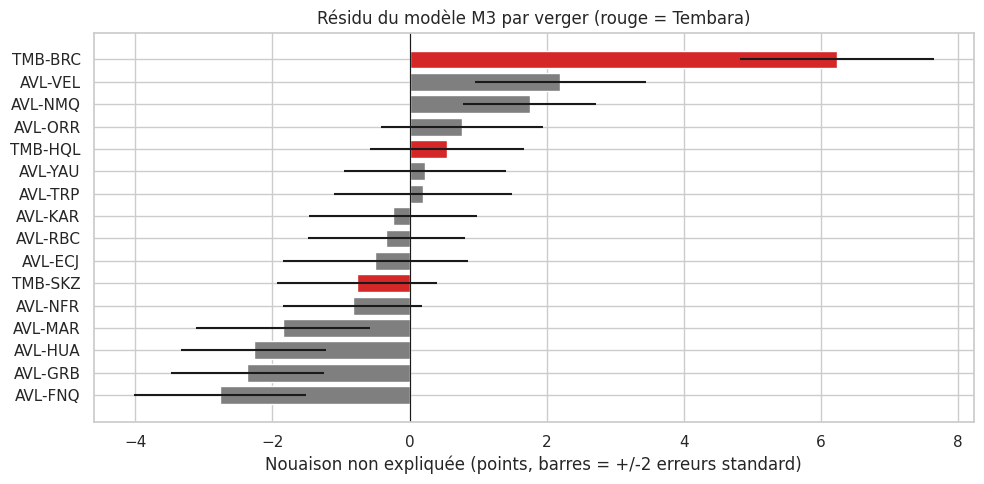

In [ ]:
def ols(y, X):
    Xm = np.column_stack([np.ones(len(X)), X]); beta = np.linalg.lstsq(Xm, y, rcond=None)[0]; pred = Xm @ beta
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum(); return beta, pred, r2

M = pd.get_dummies(orc.m, prefix="m", drop_first=True).astype(float).to_numpy()
y = orc.fs.to_numpy()
models = {"M0 : mois seul": M,
          "M1 : + fleurs": np.column_stack([M, orc.flo]),
          "M2 : + autres pollinisateurs": np.column_stack([M, orc.flo, orc.pol]),
          "M3 : + fertilisation + irrigation": np.column_stack([M, orc.flo, orc.pol, orc.fer, orc.irr])}
for name, X in models.items():
    print(f"{name:<36} R2 = {ols(y, X)[2]:.3f}")

b, pred, r2 = ols(y, models["M3 : + fertilisation + irrigation"])
print("\nCoefficients (points de nouaison par unité) :", dict(zip(["fleurs", "pollinisateurs", "fertilisation", "irrigation"], b[-4:].round(3))))
orc["res"] = y - pred                                                    # nouaison NON expliquée
b2, pred2, _ = ols(y, models["M1 : + fleurs"]); orc["res_flo"] = y - pred2   # sans pollinisateurs

rs = orc.groupby("site_code").res.agg(["mean", "std", "count"]); rs["se"] = rs["std"] / np.sqrt(rs["count"])
rs["z"] = (rs["mean"] - rs["mean"].mean()) / rs["mean"].std()
print("\nNouaison non expliquée, moyenne par verger (points) :"); print(rs.sort_values("mean", ascending=False).round(2))

fig, ax = plt.subplots(figsize=(10, 5))
o_ = rs.sort_values("mean"); ax.barh(o_.index, o_["mean"], xerr=2 * o_.se, color=np.where(o_.index.str.startswith("TMB"), "#d62728", "#7f7f7f"))
ax.axvline(0, c="k", lw=.8); ax.set_xlabel("Nouaison non expliquée (points, barres = +/-2 erreurs standard)"); ax.set_title("Résidu du modèle M3 par verger (rouge = Tembara)")
plt.tight_layout(); plt.show()

### Interprétation (cellule 8)

- Les pratiques de gestion (engrais, eau) n'expliquent rien ; les pollinisateurs sont le principal facteur identifié après le calendrier.
- TMB-BRC est le seul verger à avoir un résidu hors de l'intervalle des autres.

## Cellule 9 — Le verger TMB-BRC
on veut savoir si l'écart de `TMB-BRC` est un vrai effet ou un hasard, s'il est stable et s'il se distingue de ses voisins de Tembara.

on utilise un test de permutation


Écart moyen maximal observé : 6.24 (TMB-BRC) | simulé sous hasard : médiane 1.26, 99e percentile 2.08
p-valeur de permutation (max sur 16 vergers) : 0.0004997501249375312

Comparaison de TMB-BRC :
variable    BRC  HQL+SKZ  Avelora  p vs Tembara  p vs Avelora  d de Cohen vs Avelora
      fs   65.8     55.2     52.4  2.429625e-13  1.442770e-24                   1.54
     pol   70.0     61.9     58.3  1.378020e-10  3.839060e-22                   1.30
     flo   67.8     65.5     62.4  4.288081e-01  3.558003e-02                   0.24
     yha 1261.3   1067.6   1020.2  7.449127e-11  1.928560e-19                   1.27
     res    6.2     -0.1     -0.5  7.969647e-12  8.619645e-17                   1.24

Stabilité dans le temps (nouaison non expliquée de TMB-BRC par année) :
y       2019   2020   2021   2022   2023   2024  2025
mean    4.88   8.32   5.95   6.73   5.38   6.35  5.83
count  12.00  12.00  12.00  12.00  12.00  12.00  6.00
Pente par an : 0.02 pt (p = 0.95)


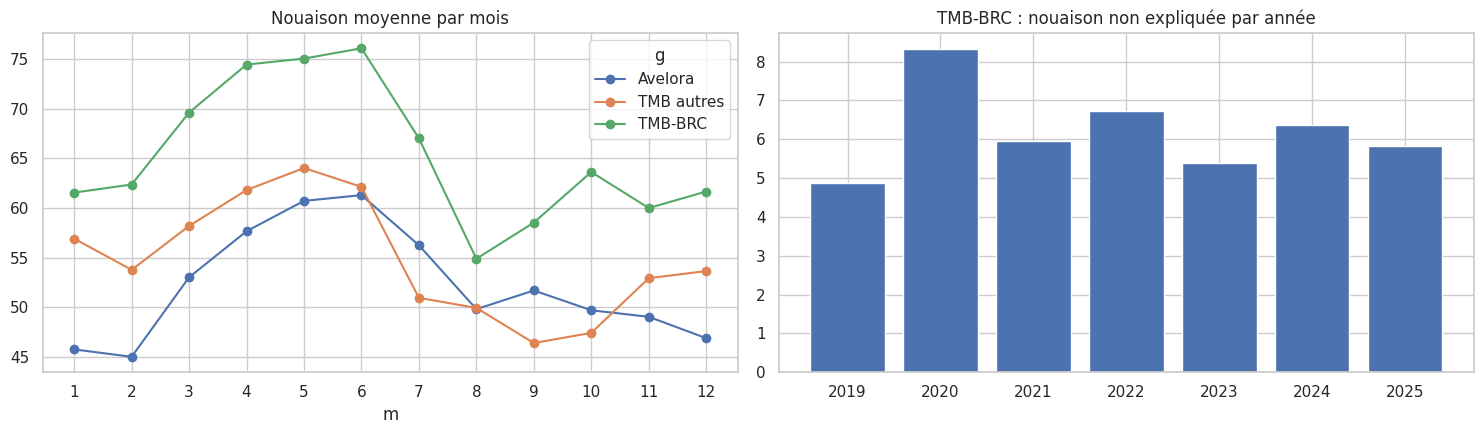

In [ ]:
rng = np.random.default_rng(0)
codes, uniq = pd.factorize(orc.site_code)
obs = pd.Series(orc.groupby("site_code").res.mean())
obs_max = obs.abs().max()
sims = np.array([np.abs(np.bincount(codes, weights=rng.permutation(orc.res.values)) / np.bincount(codes)).max() for _ in range(2000)])
print(f"Écart moyen maximal observé : {obs_max:.2f} ({obs.abs().idxmax()}) | simulé sous hasard : médiane {np.median(sims):.2f}, 99e percentile {np.percentile(sims, 99):.2f}")
print("p-valeur de permutation (max sur 16 vergers) :", (1 + (sims >= obs_max).sum()) / (len(sims) + 1))

groups = {"TMB-BRC": orc[orc.site_code == "TMB-BRC"], "TMB-HQL+SKZ": orc[orc.site_code.isin(["TMB-HQL", "TMB-SKZ"])], "Avelora": orc[orc.zone == "AVL"]}
print("\nComparaison de TMB-BRC :")
rows = []
for v in ["fs", "pol", "flo", "yha", "res"]:
    a, t_, av_ = groups["TMB-BRC"][v], groups["TMB-HQL+SKZ"][v], groups["Avelora"][v]
    rows.append((v, round(a.mean(), 1), round(t_.mean(), 1), round(av_.mean(), 1), stats.mannwhitneyu(a, t_)[1], stats.mannwhitneyu(a, av_)[1], round((a.mean() - av_.mean()) / av_.std(), 2)))
print(pd.DataFrame(rows, columns=["variable", "BRC", "HQL+SKZ", "Avelora", "p vs Tembara", "p vs Avelora", "d de Cohen vs Avelora"]).to_string(index=False))

print("\nStabilité dans le temps (nouaison non expliquée de TMB-BRC par année) :")
by_year = orc[orc.site_code == "TMB-BRC"].groupby("y").res.agg(["mean", "count"]).round(2); print(by_year.T)
lr = stats.linregress(np.arange(78), orc[orc.site_code == "TMB-BRC"].sort_values("ym").res.values); print("Pente par an : %.2f pt (p = %.2f)" % (lr.slope * 12, lr.pvalue))

mm = orc.assign(g=np.where(orc.site_code == "TMB-BRC", "TMB-BRC", np.where(orc.zone == "AVL", "Avelora", "TMB autres"))).groupby(["g", "m"]).fs.mean().unstack(0)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
mm.plot(marker="o", ax=ax[0]); ax[0].set_title("Nouaison moyenne par mois"); ax[0].set_xticks(range(1, 13))
by = orc[orc.site_code == "TMB-BRC"].groupby("y").res.mean(); ax[1].bar(by.index, by.values); ax[1].set_title("TMB-BRC : nouaison non expliquée par année"); ax[1].axhline(0, c="k", lw=.8)
plt.tight_layout(); plt.show()

### Interprétation (cellule 9)

- TMB-BRC a un avantage réel, durable et non expliqué par ses fleurs ni par les pollinisateurs mesurés. C'est le résultat le plus solide du notebook.
- Ce que cela ne prouve pas : qu'il vienne de la caverne voisine. C'est une hypothèse parmi d'autres (sol, variété, gestion non mesurée…). On sait seulement que TMB-BRC est le verger le plus proche de la caverne TMB-NAC (14 km), ce qui est l'objet de la cellule 10.

## Cellule 10 — Distance à la caverne : y a-t-il un gradient ?
 tester l'hypothèse « plus un verger est proche d'une caverne, mieux il pollinise » (H-C du notebook 1).



             fs   pol   flo     yha  res  res_flo  dist_cave_km     cave
site_code                                                               
TMB-BRC    65.8  70.0  67.8  1261.3  6.2     10.6          14.3  TMB-NAC
TMB-HQL    56.1  61.3  67.3  1077.1  0.5      1.1          22.3  TMB-NAC
TMB-SKZ    54.3  62.4  63.8  1058.1 -0.8      0.5          51.2  TMB-NAC
AVL-GRB    46.8  49.9  62.4   899.3 -2.4     -6.5         636.8  TMB-NAC
AVL-FNQ    47.8  54.4  60.4   919.8 -2.8     -4.8         646.2  TMB-NAC
AVL-MAR    53.8  64.4  63.1  1041.9 -1.8      0.3         659.4  TMB-NAC
AVL-NFR    50.4  54.7  62.2   978.8 -0.8     -2.8         663.1  TMB-NAC
AVL-KAR    50.9  55.2  61.2  1010.8 -0.2     -2.0         663.4  TMB-NAC
AVL-VEL    57.7  64.3  62.8  1120.8  2.2      4.3         666.2  TMB-NAC
AVL-NMQ    55.6  61.2  61.7  1091.3  1.8      2.6         674.5  TMB-NAC
AVL-RBC    51.6  58.0  59.8  1023.2 -0.3     -0.8         674.5  TMB-NAC
AVL-ORR    55.1  61.0  63.3  1071.0  0.8      1.5  

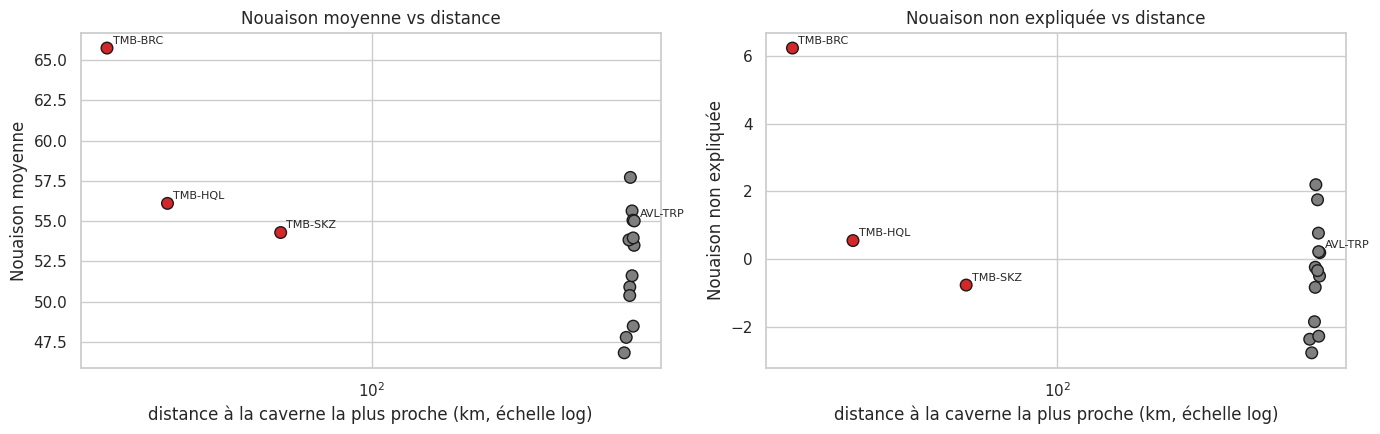

In [ ]:
R_EARTH = 6371.0
S = sites.reset_index(drop=True); Dk = haversine_distances(np.radians(S[["latitude", "longitude"]].to_numpy())) * R_EARTH
cave_idx = S.index[S.site_category == "cave monitoring"]
dist_cave = pd.Series(Dk[:, cave_idx].min(axis=1), index=S.site_code)
nearest = pd.Series(S.site_code.to_numpy()[cave_idx][Dk[:, cave_idx].argmin(axis=1)], index=S.site_code)

sm = orc.groupby("site_code")[["fs", "pol", "flo", "yha", "res", "res_flo"]].mean()
sm["dist_cave_km"] = dist_cave.loc[sm.index]; sm["cave"] = nearest.loc[sm.index]
print(sm.sort_values("dist_cave_km").round(1))

print("\nCorrélation de Spearman entre log(distance à la caverne la plus proche) et chaque variable (16 vergers) :")
for v in ["fs", "pol", "flo", "yha", "res", "res_flo"]:
    r, p = stats.spearmanr(np.log(sm.dist_cave_km), sm[v]); print(f"  {v:<8} rho = {r:+.2f} | p = {p:.2f}")

ar = orc.groupby("site_code").orchard_area_ha.first().loc[sm.index]
print("\nSurface du verger vs nouaison / nouaison non expliquée (Spearman, 16 vergers) :")
for v in ["fs", "res"]:
    r, p = stats.spearmanr(ar, sm[v]); print(f"  {v:<4} rho = {r:+.2f} | p = {p:.2f}")
print("Surface de TMB-BRC :", ar["TMB-BRC"], "ha | rang parmi les 16 (1 = plus petit) :", int(ar.rank()["TMB-BRC"]))

print("\nEn retirant TMB-BRC :")
s2 = sm.drop("TMB-BRC")
for v in ["fs", "pol", "res"]:
    r, p = stats.spearmanr(np.log(s2.dist_cave_km), s2[v]); print(f"  {v:<8} rho = {r:+.2f} | p = {p:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, v, t in zip(ax, ["fs", "res"], ["Nouaison moyenne", "Nouaison non expliquée"]):
    a.scatter(sm.dist_cave_km, sm[v], c=np.where(sm.index.str.startswith("TMB"), "#d62728", "#7f7f7f"), s=70, edgecolor="k")
    for sc, r_ in sm.iterrows():
        if sc.startswith("TMB") or sc in SPECIAL: a.annotate(sc, (r_.dist_cave_km, r_[v]), fontsize=8, xytext=(4, 3), textcoords="offset points")
    a.set_xscale("log"); a.set_xlabel("distance à la caverne la plus proche (km, échelle log)"); a.set_ylabel(t); a.set_title(t + " vs distance")
plt.tight_layout(); plt.show()

### Interprétation (cellule 10)

- L'effet d'une caverne n'est pas démontré. Un effet de pollinisation décroissant avec la distance donnerait un gradient (22 km meilleur que 51 km, meilleur que 650 km). On observe un point isolé, pas une pente.
- Mais cela ne l'exclut pas: (1) il n'y a que 3 vergers à moins de 100 km ; (2) l'effet pourrait être très local (14 km oui, 22 km non) ; (3) région et caverne sont confondues (seule Tembara a une caverne) ; (4) la caverne n'est observée qu'à travers des mesures acoustiques d'appareil, pas d'animaux.


## Cellule 11 — Le verger AVL-TRP (H-G / H-J)
 AVL-TRP est le seul des deux sites à pannes cycliques (notebook 2) qui soit un verger : se comporte-t-il autrement, en général et pendant ses mois de panne ?



=== AVL-TRP vs les 12 autres vergers d'Avelora ===
  flo  TRP   69.0 | autres   61.9 | Mann-Whitney p = 0.004
  fs   TRP   55.0 | autres   52.1 | Mann-Whitney p = 0.019
  pol  TRP   58.5 | autres   58.2 | Mann-Whitney p = 0.902
  yha  TRP 1066.8 | autres 1016.3 | Mann-Whitney p = 0.034
  res  TRP    0.2 | autres   -0.5 | Mann-Whitney p = 0.331
Densité de fleurs : écart de TRP aux 12 autres en écarts-types des moyennes de verger : 6.1
Mois saturés (= 100) : TRP 10 | moyenne des 12 autres 5.3

Différence (mois de panne - autres mois), TRP vs les 15 autres vergers :
       TRP  autres (moy.)  autres (ecart-type)  z de TRP
flo   5.24           4.20                 1.84      0.56
fs   -1.93           1.08                 1.81     -1.66
pol   0.99          -0.02                 1.57      0.65
yha -47.34          22.30                42.13     -1.65
res  -3.56           0.24                 1.38     -2.74

Test t (TRP vs 15 autres) :
         t      p  p corrigé (Bonferroni x5)
flo  0.546  0.

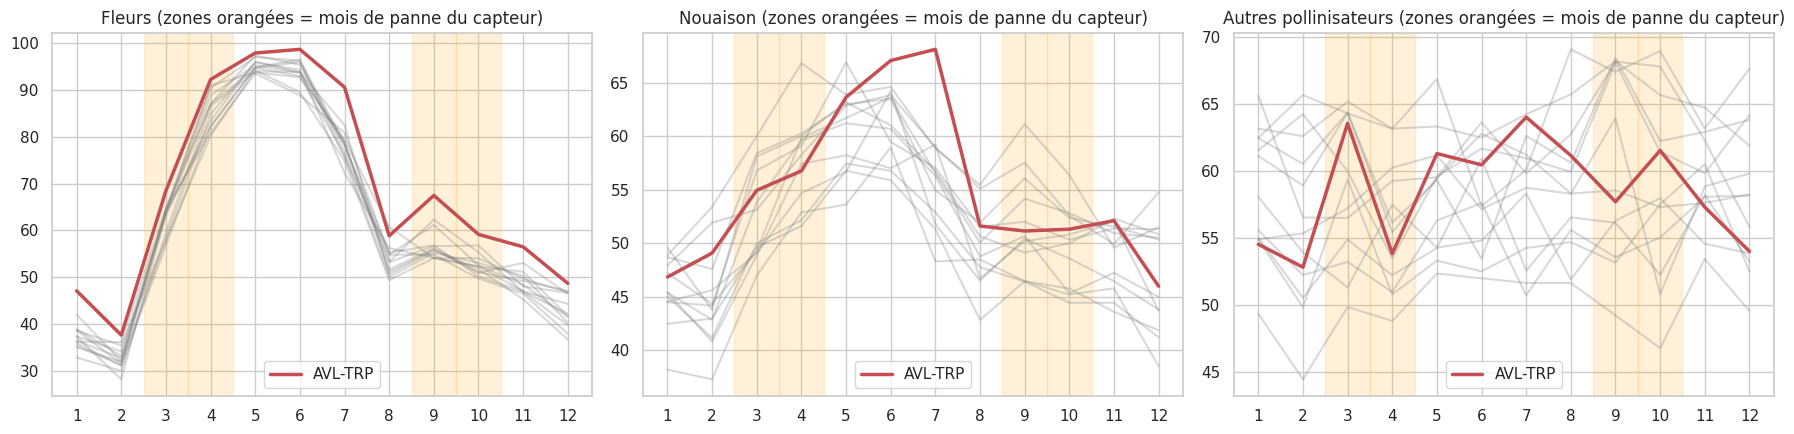

In [ ]:
trp = orc[orc.site_code == "AVL-TRP"]; av_o = orc[(orc.zone == "AVL") & (orc.site_code != "AVL-TRP")]
print("=== AVL-TRP vs les 12 autres vergers d'Avelora ===")
for v in ["flo", "fs", "pol", "yha", "res"]:
    print(f"  {v:<4} TRP {trp[v].mean():6.1f} | autres {av_o[v].mean():6.1f} | Mann-Whitney p = {stats.mannwhitneyu(trp[v], av_o[v])[1]:.3f}")
means = av_o.groupby("site_code").flo.mean()
print("Densité de fleurs : écart de TRP aux 12 autres en écarts-types des moyennes de verger : %.1f" % ((trp.flo.mean() - means.mean()) / means.std()))
print("Mois saturés (= 100) : TRP", int(trp.flo_sat.sum()), "| moyenne des 12 autres", round(av_o.groupby("site_code").flo_sat.sum().mean(), 1))

# Les fenêtres de panne (mars, avril, sept., oct.) : TRP se comporte-t-il autrement qu'en dehors, par rapport aux autres vergers ?
rows = []
for sc, g in orc.groupby("site_code"):
    gw, go = g[g.m.isin(WINDOWS)], g[~g.m.isin(WINDOWS)]
    rows.append((sc, *[gw[v].mean() - go[v].mean() for v in ["flo", "fs", "pol", "yha", "res"]]))
dd = pd.DataFrame(rows, columns=["site", "flo", "fs", "pol", "yha", "res"]).set_index("site")
others = dd.drop("AVL-TRP")
z = (dd.loc["AVL-TRP"] - others.mean()) / others.std()
print("\nDifférence (mois de panne - autres mois), TRP vs les 15 autres vergers :")
print(pd.DataFrame({"TRP": dd.loc["AVL-TRP"], "autres (moy.)": others.mean(), "autres (ecart-type)": others.std(), "z de TRP": z}).round(2))
n_o = len(others)
tstat = (dd.loc["AVL-TRP"] - others.mean()) / (others.std() * np.sqrt(1 + 1 / n_o))       # une observation vs un échantillon de 15
pv = pd.Series(2 * stats.t.sf(np.abs(tstat), df=n_o - 1), index=tstat.index)
print("\nTest t (TRP vs 15 autres) :"); print(pd.DataFrame({"t": tstat, "p": pv, "p corrigé (Bonferroni x5)": (pv * 5).clip(upper=1)}).round(3))

# Densité de fleurs : TRP est-il le plus élevé par hasard ? (permutation du maximum sur 16 vergers)
dflo = (orc.flo - orc.groupby("m").flo.transform("mean")).to_numpy()
codes, uniq = pd.factorize(orc.site_code); rng = np.random.default_rng(1)
obs_f = pd.Series(np.bincount(codes, weights=dflo) / np.bincount(codes), index=uniq)
sims = np.array([(np.bincount(codes, weights=rng.permutation(dflo)) / np.bincount(codes)).max() for _ in range(2000)])
print("\nÉcart de fleurs au mois moyen, 3 vergers les plus hauts :", obs_f.sort_values(ascending=False).head(3).round(1).to_dict())
print("Maximum simulé sous hasard : médiane %.1f, 95e percentile %.1f | p (max sur 16 vergers) = %.3f" % (np.median(sims), np.percentile(sims, 95), (1 + (sims >= obs_f.max()).sum()) / 2001))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, v, t in zip(ax, ["flo", "fs", "pol"], ["Fleurs", "Nouaison", "Autres pollinisateurs"]):
    for sc, g in av_o.groupby("site_code"): a.plot(range(1, 13), g.groupby("m")[v].mean().values, c="gray", alpha=.3)
    a.plot(range(1, 13), trp.groupby("m")[v].mean().values, c="r", lw=2.5, label="AVL-TRP")
    for mth in WINDOWS: a.axvspan(mth - .5, mth + .5, color="orange", alpha=.15)
    a.set_title(t + " (zones orangées = mois de panne du capteur)"); a.set_xticks(range(1, 13)); a.legend()
plt.tight_layout(); plt.show()

### Interprétation (cellule 11)


- H-J (le verger réagit pendant les fenêtres de panne) : non soutenue. Un indice très faible dans la bonne direction, qui ne résiste pas à la correction.
- Fait nouveau :AVL-TRP est atypique dans deux tables : pannes cycliques d'appareil  et floraison exceptionnellement haute (ici). Ce peut être un hasard : un site spécial a une probabilité d'environ 1/16 (≈ 6 %) de tomber sur le verger le plus fleuri ; ce n'est pas assez rare pour parler de lien.

## Cellule 12 — Mois atypiques : Isolation Forest, LOF, z-score modifié
 repérer les **mois** (verger × mois) atypiques.



In [ ]:
# Niveau ligne : mois atypiques. On retire la saison moyenne de chaque variable, puis on standardise.
F = pd.DataFrame({v: orc[v] - orc.groupby("m")[v].transform("mean") for v in ["flo", "fs", "pol", "yha"]})
Zf = StandardScaler().fit_transform(F)
iso = IsolationForest(n_estimators=300, contamination=0.01, random_state=0).fit(Zf); orc["iso"] = -iso.score_samples(Zf)
lof = LocalOutlierFactor(n_neighbors=25).fit(Zf); orc["lof"] = -lof.negative_outlier_factor_
cols = ["site_code", "survey_period", "flo", "fs", "pol", "yha", "note", "fs_rescaled"]
print("Top 8 mois atypiques (Isolation Forest) :"); print(orc.nlargest(8, "iso")[cols + ["iso"]].round(2).to_string(index=False))
print("\nTop 8 mois atypiques (LOF) :"); print(orc.nlargest(8, "lof")[cols + ["lof"]].round(2).to_string(index=False))
top_if = set(orc.nlargest(15, "iso").index); top_lof = set(orc.nlargest(15, "lof").index)
print("\nMois dans le top 15 des DEUX méthodes :", len(top_if & top_lof))
print("Part des mois atypiques portant une note de perturbation :", round(orc.loc[list(top_if | top_lof), "note"].notna().mean(), 2), "| part de tous les mois :", round(orc.note.notna().mean(), 3))
print("Sites les plus représentés dans le top 15 Isolation Forest :", orc.loc[list(top_if), "site_code"].value_counts().head(4).to_dict())

# Z-score modifié sur la nouaison non expliquée (échelle commune)
res = orc.res.values; med = np.median(res); mad = np.median(np.abs(res - med)); orc["zmod"] = 0.6745 * (res - med) / mad
print("\nMois avec |z modifié| > 3,5 sur la nouaison non expliquée :", (orc.zmod.abs() > 3.5).sum(), "sur", len(orc))
print(orc.loc[orc.zmod.abs() > 3.5, "site_code"].value_counts().head(5).to_dict())

Top 8 mois atypiques (Isolation Forest) :
site_code survey_period   flo   fs  pol     yha note  fs_rescaled  iso
  TMB-BRC    2025-02-01  63.6 75.0 79.0 1340.03  NaN        False 0.69
  TMB-BRC    2022-01-01  77.0 71.0 79.4 1309.92  NaN        False 0.68
  TMB-BRC    2020-12-01  57.9 71.2 82.7 1407.73  NaN        False 0.67
  AVL-RBC    2020-04-01  73.0 71.6 86.0 1560.76  NaN        False 0.66
  TMB-BRC    2020-02-01  61.0 68.2 72.8 1402.21  NaN        False 0.66
  AVL-HUA    2022-02-01  20.8 27.3 41.8  454.27  NaN        False 0.66
  TMB-BRC    2025-01-01  72.6 71.0 70.6 1294.82  NaN        False 0.65
  TMB-BRC    2023-04-01 100.0 87.7 78.2 1562.12  NaN        False 0.65

Top 8 mois atypiques (LOF) :
site_code survey_period   flo   fs  pol     yha                      note  fs_rescaled  lof
  TMB-SKZ    2021-07-01  41.0 53.2 64.0 1008.53                       NaN        False 1.97
  TMB-BRC    2023-08-01  38.5 56.1 93.7 1160.74                       NaN        False 1.95
  AVL-FNQ    

### Interprétation (cellule 12)

 les données ne contiennent pas de grappe d'événements anormaux ; les écarts sont surtout des différences de niveau entre vergers. C'est cohérent avec la cellule 8.

## Cellule 13 — Notes de perturbation
comprendre où et quand les 23 notes apparaissent, et si elles correspondent à un effet mesurable.



Notes : 23 | par type : {'storm-related flower loss': 18, 'elevated pesticide application': 5}
Notes par verger : {'AVL-FNQ': 16, 'AVL-GRB': 2, 'TMB-HQL': 2, 'AVL-MAR': 1, 'AVL-NFR': 1, 'AVL-YAU': 1}
Notes par mois   : {1: 2, 2: 1, 5: 2, 6: 1, 9: 3, 10: 8, 11: 3, 12: 3}

Verger le plus concerné : AVL-FNQ (16/23). Loi binomiale (p = 1/16) : P(X >= 16) = 8.7e-15

Écart moyen des mois notés par rapport au même verger / même mois calendaire :
                          note       variable  n  écart moyen  p (Mann-Whitney)
     storm-related flower loss         fleurs 18         0.26             0.952
     storm-related flower loss       nouaison 18        -1.01             0.354
     storm-related flower loss   rendement/ha 18       -18.92             0.593
     storm-related flower loss pollinisateurs 18         0.04             0.984
elevated pesticide application         fleurs  5        -2.90             0.297
elevated pesticide application       nouaison  5        -4.19             0.2

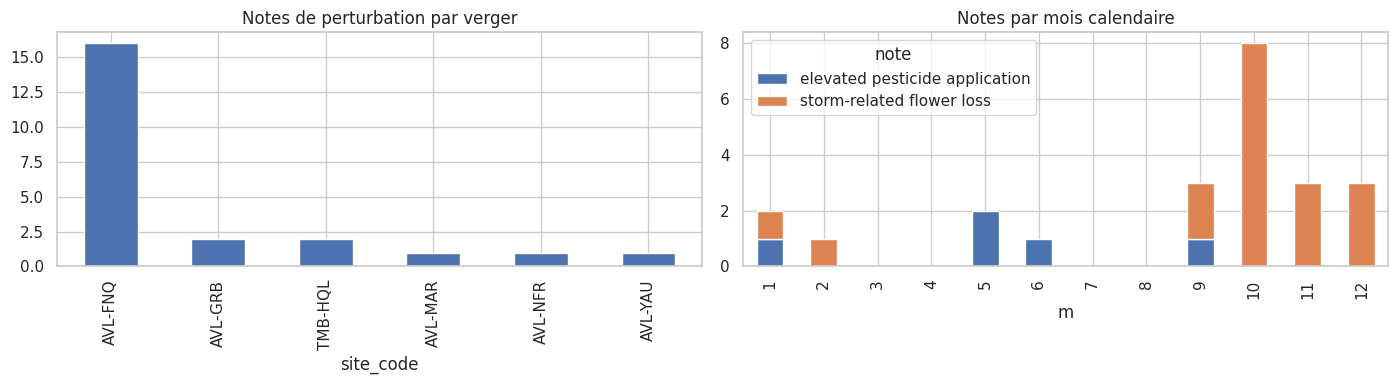

In [ ]:
notes = orc[orc.note.notna()]
print("Notes :", len(notes), "| par type :", notes.note.value_counts().to_dict())
print("Notes par verger :", notes.site_code.value_counts().to_dict())
print("Notes par mois   :", notes.m.value_counts().sort_index().to_dict())

# Concentration : si les 23 notes étaient tirées au hasard parmi 16 vergers, quelle probabilité d'en avoir >= k sur un verger ?
k = notes.site_code.value_counts().iloc[0]; top = notes.site_code.value_counts().index[0]
print(f"\nVerger le plus concerné : {top} ({k}/{len(notes)}). Loi binomiale (p = 1/16) : P(X >= {k}) = {stats.binom.sf(k - 1, len(notes), 1 / 16):.1e}")

# Effet des notes : écart à la moyenne du MÊME verger et du MÊME mois calendaire
for v in ["flo", "fs", "yha", "pol"]:
    orc["r_" + v] = orc[v] - orc.groupby(["site_code", "m"])[v].transform("mean")
rows = []
for nt in ["storm-related flower loss", "elevated pesticide application"]:
    for v, lab in [("flo", "fleurs"), ("fs", "nouaison"), ("yha", "rendement/ha"), ("pol", "pollinisateurs")]:
        a, b = orc[orc.note == nt]["r_" + v], orc[orc.note.isna()]["r_" + v]
        rows.append((nt, lab, int(len(a)), round(a.mean(), 2), round(stats.mannwhitneyu(a, b)[1], 3)))
print("\nÉcart moyen des mois notés par rapport au même verger / même mois calendaire :")
print(pd.DataFrame(rows, columns=["note", "variable", "n", "écart moyen", "p (Mann-Whitney)"]).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
notes.site_code.value_counts().plot.bar(ax=ax[0]); ax[0].set_title("Notes de perturbation par verger")
notes.groupby(["m", "note"]).size().unstack(fill_value=0).reindex(range(1, 13), fill_value=0).plot.bar(stacked=True, ax=ax[1]); ax[1].set_title("Notes par mois calendaire")
plt.tight_layout(); plt.show()

### Interprétation (cellule 13)

- Les notes décrivent surtout un verger (AVL-FNQ), pas un phénomène général. Elles ne correspondent à aucun effet quantifiable sur les mesures. Hypothèse : étiquette descriptive sans lien avec les valeurs (cohérent avec l'indépendance engrais/irrigation).
- AVL-FNQ est un verger « à part » dans plusieurs tables : 16 notes ici, et il figurait au notebook 2 parmi les sites les plus atypiques des sites normaux (qualité acoustique moyenne la plus basse : 76,4).

## Cellule 14 — Tendances et tests multiples
 savoir si les vergers s'améliorent ou se dégradent entre 2019 et 2025.



In [ ]:
orc["tt"] = (orc.y - 2019) * 12 + orc.m - 1
for v in ["fs", "flo", "yha", "pol"]:
    orc["d_" + v] = orc[v] - orc.groupby(["site_code", "m"])[v].transform("mean")        # désaisonnalisation par verger
rows = []
for sc, g in orc.groupby("site_code"):
    for v in ["fs", "flo", "yha", "pol"]:
        lr = stats.linregress(g.tt, g["d_" + v]); rows.append((sc, v, lr.slope * 12, lr.pvalue))
tr = pd.DataFrame(rows, columns=["site", "variable", "pente_par_an", "p"])
m_ = len(tr); order = np.argsort(tr.p.values); q = np.empty(m_); prev = 1.0
for rank, i in reversed(list(enumerate(order, start=1))):
    prev = min(prev, tr.p.values[i] * m_ / rank); q[i] = prev
tr["q_BH"] = q
print(tr.sort_values("p").head(6).round(3).to_string(index=False))
print("\nTests : %d | p < 0,05 : %d | attendu par hasard : %.1f | plus petit q (BH) : %.2f" % (m_, (tr.p < .05).sum(), .05 * m_, tr.q_BH.min()))
print("\nPente moyenne par variable (par an) :"); print(tr.groupby("variable").pente_par_an.agg(["mean", "std"]).round(2))
print("\nTembara (BRC, HQL, SKZ) - pente moyenne de la nouaison :", tr[(tr.variable == "fs") & tr.site.str.startswith("TMB")].set_index("site").pente_par_an.round(2).to_dict())

# Attention : 2025 n'a que 6 mois (janv.-juin, avec la haute saison)
naive = orc.groupby("y").fs.mean().round(1); fair = orc[orc.m <= 6].groupby("y").fs.mean().round(1)
print("\nNouaison moyenne par année, calendrier brut (2025 incomplet)  :", naive.to_dict())
print("Nouaison moyenne par année, janvier-juin seulement (équitable) :", fair.to_dict())

   site variable  pente_par_an     p  q_BH
AVL-VEL      pol         1.154 0.014 0.871
AVL-NFR      yha        16.363 0.032 0.871
AVL-KAR      pol        -0.881 0.044 0.871
AVL-NFR       fs         0.566 0.054 0.871
AVL-HUA      flo        -0.731 0.100 0.996
AVL-MAR       fs         0.550 0.121 0.996

Tests : 64 | p < 0,05 : 3 | attendu par hasard : 3.2 | plus petit q (BH) : 0.87

Pente moyenne par variable (par an) :
          mean   std
variable            
flo      -0.11  0.35
fs        0.06  0.31
pol      -0.03  0.44
yha       1.98  7.49

Tembara (BRC, HQL, SKZ) - pente moyenne de la nouaison : {'TMB-BRC': 0.03, 'TMB-HQL': 0.06, 'TMB-SKZ': -0.48}

Nouaison moyenne par année, calendrier brut (2025 incomplet)  : {2019: 53.0, 2020: 53.3, 2021: 53.2, 2022: 54.3, 2023: 53.2, 2024: 53.3, 2025: 55.6}
Nouaison moyenne par année, janvier-juin seulement (équitable) : {2019: 55.0, 2020: 55.7, 2021: 55.2, 2022: 56.2, 2023: 55.6, 2024: 55.9, 2025: 55.6}


### Interprétation (cellule 14)
 les vergers sont stable sur 7 ans : ni amélioration, ni dégradation. Donc l'avantage de TMB-BRC n'est pas une dérive récente, c'est un état permanent.

## Cellule 15 — Profils de vergers : PCA, Ward, k-means, DBSCAN
 regrouper les 16 vergers selon l'ensemble de leurs caractéristiques et repérer les isolés .



Variance expliquée PCA : [0.51 0.19]
          PC1   PC2
fs       0.46 -0.27
pol      0.42 -0.37
flo      0.39  0.28
yha      0.45 -0.30
fs_std   0.36  0.38
fs_amp   0.26  0.60
flo_amp  0.02 -0.34
notes   -0.25 -0.05

Top 4 Isolation Forest : ['TMB-BRC', 'AVL-FNQ', 'AVL-GRB', 'TMB-HQL']
Top 4 LOF              : ['TMB-BRC', 'AVL-FNQ', 'AVL-TRP', 'TMB-HQL']

Ward (k=3) :
zone   AVL  TMB
ward3          
1        1    2
2       11    1
3        1    0
Sites par cluster Ward : {1: ['AVL-TRP', 'TMB-BRC', 'TMB-HQL'], 2: ['AVL-ECJ', 'AVL-GRB', 'AVL-HUA', 'AVL-KAR', 'AVL-MAR', 'AVL-NFR', 'AVL-NMQ', 'AVL-ORR', 'AVL-RBC', 'AVL-VEL', 'AVL-YAU', 'TMB-SKZ'], 3: ['AVL-FNQ']}
ARI Ward vs zone : 0.33 | ARI k-means vs Ward : 0.43
DBSCAN (eps=2,2 ; min_samples=2) bruit : ['AVL-FNQ', 'AVL-GRB', 'AVL-KAR', 'TMB-BRC']


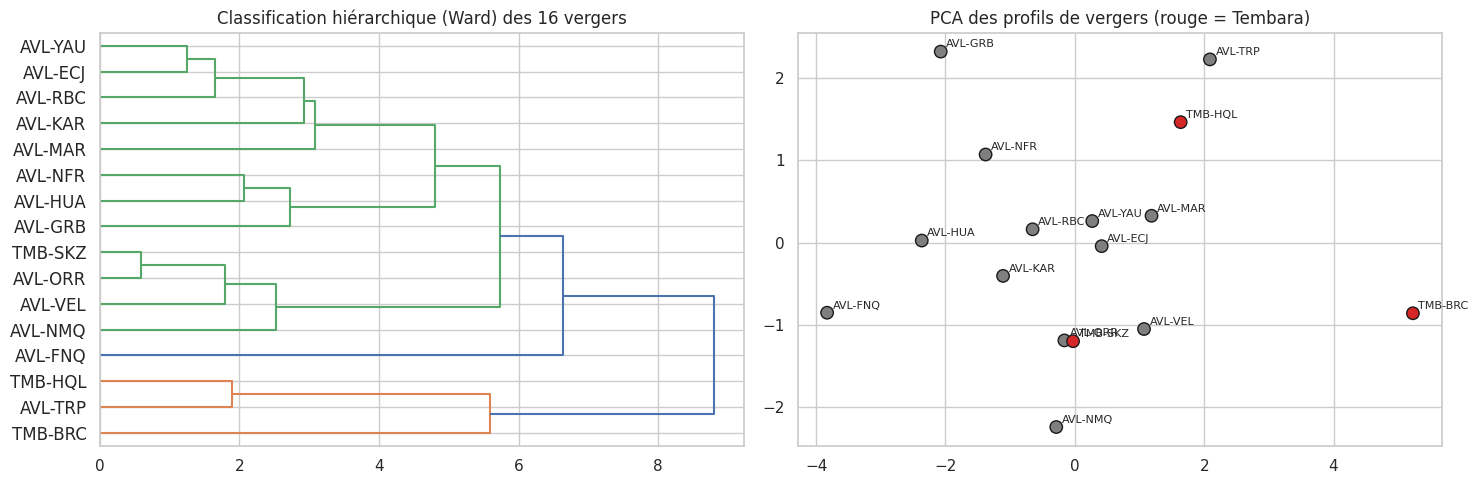

In [ ]:
P = orc.groupby("site_code").agg(fs=("fs", "mean"), pol=("pol", "mean"), flo=("flo", "mean"), yha=("yha", "mean"), fs_std=("fs", "std"),
                                  res=("res", "mean"), notes=("note", lambda x: x.notna().sum()))
P["fs_amp"] = orc.groupby(["site_code", "m"]).fs.mean().unstack().pipe(lambda d: d.max(axis=1) - d.min(axis=1))
P["flo_amp"] = orc.groupby(["site_code", "m"]).flo.mean().unstack().pipe(lambda d: d.max(axis=1) - d.min(axis=1))
P["zone"] = P.index.str[:3]
cols = ["fs", "pol", "flo", "yha", "fs_std", "fs_amp", "flo_amp", "notes"]
Z = StandardScaler().fit_transform(P[cols])

pca = PCA(2, random_state=0).fit(Z); XY = pca.transform(Z)
print("Variance expliquée PCA :", pca.explained_variance_ratio_.round(2))
print(pd.DataFrame(pca.components_.T, index=cols, columns=["PC1", "PC2"]).round(2))

iso = IsolationForest(n_estimators=300, contamination=0.15, random_state=0).fit(Z); P["iso"] = -iso.score_samples(Z)
lof = LocalOutlierFactor(n_neighbors=4).fit(Z); P["lof"] = -lof.negative_outlier_factor_
print("\nTop 4 Isolation Forest :", P.nlargest(4, "iso").index.tolist()); print("Top 4 LOF              :", P.nlargest(4, "lof").index.tolist())

L = linkage(Z, method="ward")
P["ward3"] = fcluster(L, 3, criterion="maxclust"); P["km3"] = KMeans(3, n_init=10, random_state=0).fit(Z).labels_
print("\nWard (k=3) :"); print(pd.crosstab(P.ward3, P.zone)); print("Sites par cluster Ward :", {k: v.index.tolist() for k, v in P.groupby("ward3")})
print("ARI Ward vs zone :", round(adjusted_rand_score(P.zone, P.ward3), 2), "| ARI k-means vs Ward :", round(adjusted_rand_score(P.km3, P.ward3), 2))
db = DBSCAN(eps=2.2, min_samples=2).fit(Z); P["dbscan"] = db.labels_; print("DBSCAN (eps=2,2 ; min_samples=2) bruit :", P.index[P.dbscan == -1].tolist())

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
dendrogram(L, labels=P.index.tolist(), orientation="right", ax=ax[0]); ax[0].set_title("Classification hiérarchique (Ward) des 16 vergers")
ax[1].scatter(XY[:, 0], XY[:, 1], c=np.where(P.zone == "TMB", "#d62728", "#7f7f7f"), s=80, edgecolor="k")
for i, sc in enumerate(P.index): ax[1].annotate(sc, XY[i], fontsize=8, xytext=(4, 3), textcoords="offset points")
ax[1].set_title("PCA des profils de vergers (rouge = Tembara)")
plt.tight_layout(); plt.show()

### Interprétation (cellule 15)

- Les deux extrêmes sont TMB-BRC (le meilleur) et AVL-FNQ (le plus « problématique » : 16 notes, nouaison non expliquée la plus basse, −2,8, mais non significatif).
- AVL-TRP ressort avec les vergers à floraison dense, pas avec les « anormaux » en nouaison. Les vergers ne sont pas structurés par la zone géographique mais par leur profil individuel.
- avec 16 vergers, les clusters sont instables ; on s'appuie surtout sur la convergence des méthodes.

## Cellule 16 — Export

- `orchard_surveys_clean.csv` : table nettoyée (1 248 lignes), avec les résidus du modèle (`res`) ;
- `orchard_site_profiles.csv` : un profil par verger (indicateurs, scores d'anomalie, distance à la caverne).

In [ ]:
out = orc[["orchard_survey_id", "site_code", "zone", "region", "survey_period", "y", "m", "ym", "orchard_area_ha", "flo", "fs", "pol", "yld", "yha", "fer", "irr",
           "note", "fs_rescaled", "flo_sat", "res"]].copy()
out["ym"] = out.ym.astype(str)
out.to_csv("orchard_surveys_clean.csv", index=False)
P_out = P.join(sm[["dist_cave_km", "cave"]]).reset_index()
P_out.to_csv("orchard_site_profiles.csv", index=False)
print("Sauvegardé : orchard_surveys_clean.csv", out.shape, "| orchard_site_profiles.csv", P_out.shape)
try:
    from google.colab import files
    files.download("orchard_surveys_clean.csv"); files.download("orchard_site_profiles.csv")
except ImportError:
    pass

Sauvegardé : orchard_surveys_clean.csv (1248, 20) | orchard_site_profiles.csv (16, 18)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Synthèse du notebook 3

###  Faits établis (calculés)
1. **Table complète après nettoyage** : 16 vergers × 78 mois = 1 248 lignes (2 doublons, 10 unités collées, 8 virgules, 8 nouaisons en fraction corrigées par une inférence signalée).
2. **Chaîne agronomique attendue** : nouaison ← fleurs (+0,29 pt/pt) et autres pollinisateurs (+0,44) ; rendement/ha ← nouaison (ρ = 0,91). R² = 0,63.
3. **La fertilisation et l'irrigation n'ont aucun effet** (|ρ| ≤ 0,07, gain de R² de 0,001). Fleurs et pollinisateurs sont indépendants (ρ = 0,03). Pollinisateurs sans cycle annuel.
4. **TMB-BRC est le résultat le plus solide** : +6,2 points de nouaison **non expliqués**, p ≈ 0,0005 (permutation sur 16 vergers), stable sur 7 ans, nettement distinct de ses voisins de Tembara (65,8 contre 55,2), non lié à la surface.
5. **Pas de gradient avec la distance à la caverne** : TMB-HQL (22 km) et TMB-SKZ (51 km) sont ordinaires ; TMB-BRC (14 km) est un point isolé (ρ = −0,11, p = 0,69 sur 16 vergers).
6. **AVL-TRP a la floraison la plus haute** (+5,8 pts au-dessus du mois moyen, permutation p < 0,001), ce qui explique sa nouaison et son rendement un peu supérieurs ; ses pollinisateurs et sa nouaison non expliquée sont normaux.
7. **Cycle annuel (un seul pic) avec phase régionale** : Tembara fleurit environ 1,6 mois plus tôt qu'Avelora.
8. **Aucune tendance significative** (3/64 tests à p < 0,05 pour 3,2 attendus ; q min = 0,87) ; le « pic 2025 » est un artefact de calendrier.
9. **Notes de perturbation :** 23 au total, **16 à AVL-FNQ ** (p ≈ 10⁻¹⁴), sans effet mesurable sur les fleurs, la nouaison ou le rendement.




